# 2 · Modelos y búsqueda de hiperparámetros

| Modelo | Idea | Sirve para usuario nuevo |
|---|---|---|
| Popularidad global | lo más gustado de la historia | sí (lo mismo para todos) |
| Popularidad reciente | lo más gustado en los últimos 180 días | sí |
| **ALS implícito** (`implicit`) | factoriza la matriz usuario × película con confianza α (Hu, Koren y Volinsky 2008) | con *fold-in* |
| **Contenido** | perfil = promedio de los vectores [genome (SVD 64) · géneros] de lo que le gustó | sí, incluso solo con géneros |
| **Híbrido** | w·z(ALS) + (1−w)·z(contenido) + β·z(recientes), w = n/(n+k) | sí |
| EASE (referencia) | autoencoder lineal item-item de forma cerrada (Steck 2019) | sí, pero B pesa 1,2 GB: no va a la API |

Toda la búsqueda se hace en **validación** (entrenar < 2017-07, evaluar 2017-07 → 2017-12).

In [1]:
import json, sys
import numpy as np, pandas as pd
from IPython.display import Image, display
from recomendador import config as C
sys.path.insert(0, str(C.RAIZ))  # para importar api.main
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## ALS: 10 configuraciones, no la rejilla completa

Se probaron factores (64/128/256), regularización λ, confianza α y la ponderación BM25.

In [2]:
als = pd.read_csv(C.REPORTES / "busqueda_als.csv").drop(columns="config")
als.sort_values("ndcg_existentes", ascending=False)

,factores,regularizacion,alpha,bm25,segundos_ajuste,ndcg_existentes,recall_existentes,ndcg_nuevos,ndcg_todos,ndcg_medios,ndcg_muchos,ndcg_pocos
7,128,1.0000,2,True,118.5000,0.1179,0.0681,0.3605,0.2233,0.1365,0.1016,0.2048
11,128,1.0000,1,True,31.6000,0.1166,0.0661,0.3605,0.2225,0.1343,0.1013,0.1973
9,256,1.0000,2,True,86.6000,0.1145,0.0667,0.3531,0.2181,0.1321,0.1008,0.1766
10,64,1.0000,2,True,36.1000,0.1143,0.0664,0.3581,0.2202,0.1321,0.0987,0.1983
0,64,0.1000,10,False,49.8000,0.1081,0.0660,0.3525,0.2143,0.1292,0.0900,0.2039
5,128,10.0000,10,False,76.8000,0.1074,0.0624,0.3677,0.2205,0.1291,0.0881,0.2122
2,128,1.0000,10,False,67.9000,0.1071,0.0621,0.3679,0.2203,0.1293,0.0877,0.2113
4,128,0.1000,2,False,81.0000,0.1069,0.0606,0.3332,0.2052,0.1223,0.0929,0.1852
1,128,0.1000,10,False,88.4000,0.1066,0.0613,0.3682,0.2203,0.1293,0.0870,0.2108
6,256,1.0000,10,False,116.2000,0.1038,0.0602,0.3607,0.2154,0.1288,0.0843,0.1933


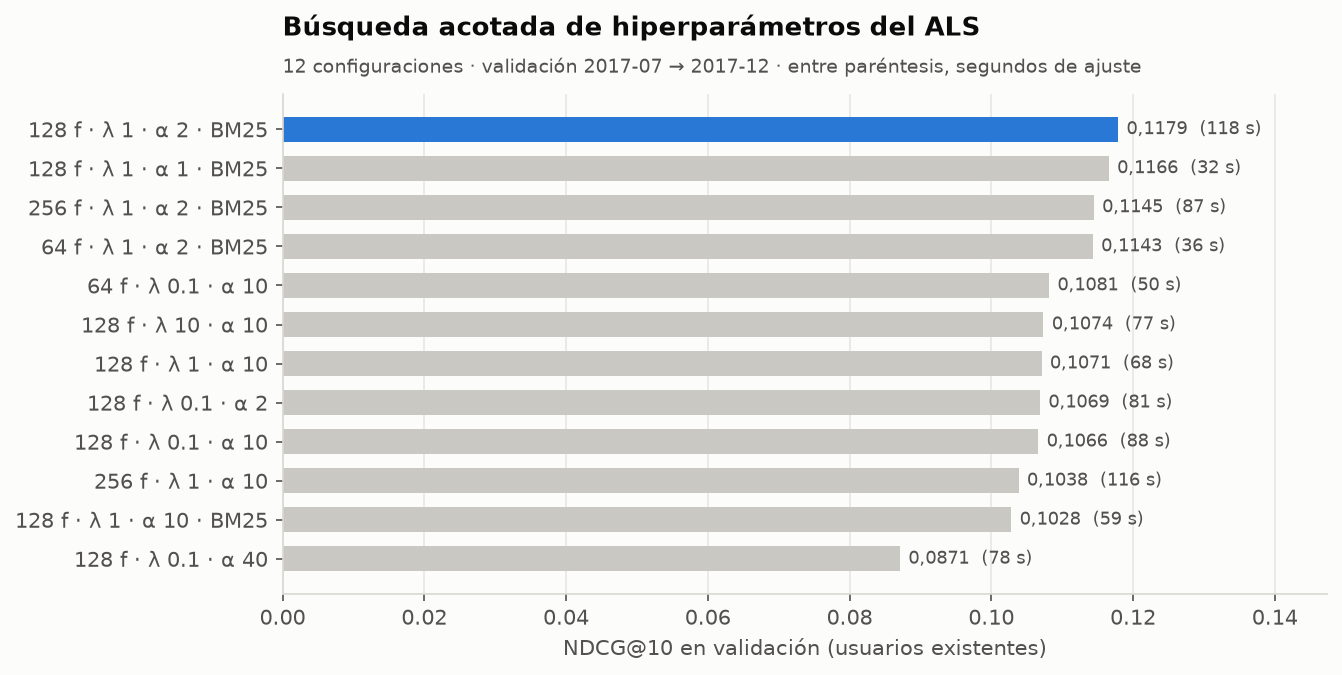

In [3]:
display(Image(str(C.FIGURAS / "04_busqueda_als.png")))

## Contenido: peso de los géneros frente al genome y prior de popularidad

In [4]:
pd.read_csv(C.REPORTES / "busqueda_contenido.csv").drop(columns="config").sort_values("ndcg_todos", ascending=False)

,peso_generos,peso_popularidad,ndcg_existentes,recall_existentes,ndcg_nuevos,ndcg_todos,ndcg_medios,ndcg_muchos,ndcg_pocos
2,0.2000,0.3000,0.0849,0.0455,0.3385,0.1950,0.0981,0.0689,0.2003
1,0.2000,0.1000,0.0876,0.0496,0.3329,0.1941,0.1046,0.0715,0.1816
3,0.2000,0.6000,0.0800,0.0423,0.3353,0.1909,0.0895,0.0650,0.2035
7,0.5000,0.6000,0.0775,0.0414,0.3251,0.1850,0.0884,0.0622,0.1970
6,0.5000,0.3000,0.0793,0.0414,0.3221,0.1847,0.0929,0.0634,0.1904
5,0.5000,0.1000,0.0750,0.0402,0.2964,0.1712,0.0905,0.0603,0.1615
0,0.2000,0.0000,0.0624,0.0405,0.2755,0.1549,0.0793,0.0486,0.1297
4,0.5000,0.0000,0.0499,0.0298,0.2253,0.1261,0.0650,0.0377,0.1092


## Híbrido: k (cuándo confiar en el ALS) y β (popularidad reciente)

In [5]:
pd.read_csv(C.REPORTES / "busqueda_hibrido.csv").drop(columns="config").sort_values("ndcg_todos", ascending=False).head(8)

,k,peso_reciente,ndcg_existentes,recall_existentes,ndcg_nuevos,ndcg_todos,ndcg_medios,ndcg_muchos,ndcg_pocos
16,30,2.0000,0.1318,0.0778,0.4028,0.2495,0.1464,0.1130,0.2712
17,100,2.0000,0.1323,0.0783,0.3951,0.2464,0.1475,0.1141,0.2615
15,100,1.0000,0.1308,0.0762,0.3967,0.2463,0.1487,0.1111,0.2643
11,30,1.0000,0.1277,0.0744,0.3999,0.2459,0.1433,0.1089,0.2624
14,100,0.5000,0.1277,0.0737,0.3916,0.2423,0.1462,0.1078,0.2592
10,30,0.5000,0.1252,0.0734,0.3934,0.2417,0.1420,0.1065,0.2514
18,300,1.0000,0.1278,0.0742,0.3885,0.2410,0.1430,0.1106,0.2465
13,100,0.2500,0.1254,0.0719,0.3871,0.2391,0.1449,0.1055,0.2513


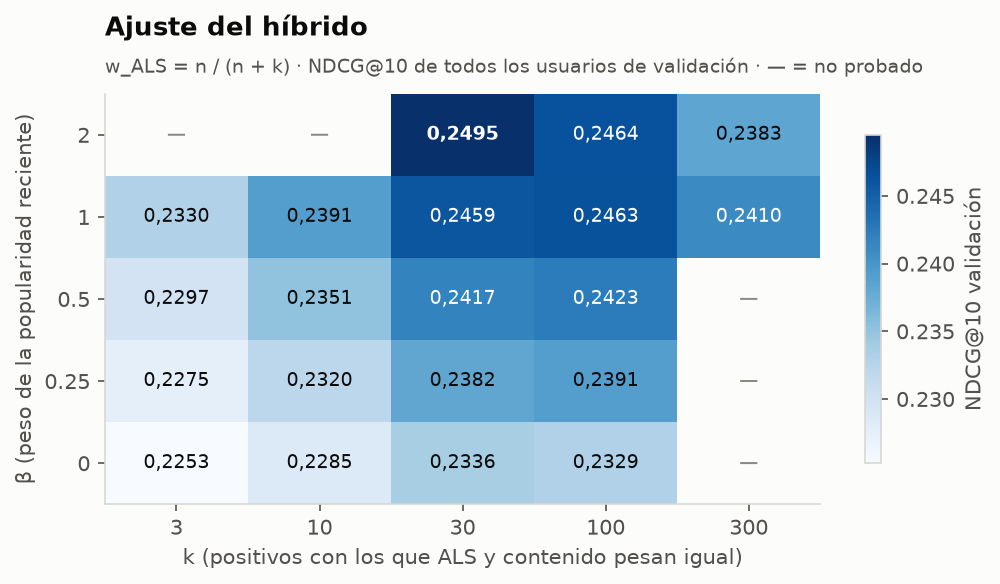

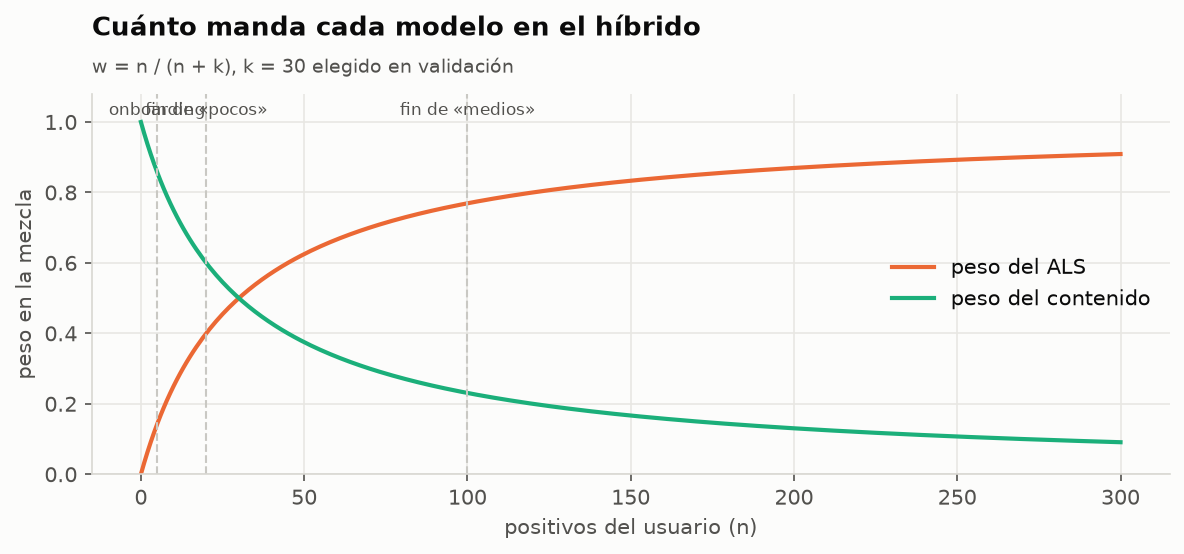

In [6]:
display(Image(str(C.FIGURAS / "05_hibrido_rejilla.png")))
display(Image(str(C.FIGURAS / "07_peso_hibrido.png")))

## EASE como referencia fuerte

In [7]:
pd.read_csv(C.REPORTES / "busqueda_ease.csv").drop(columns="config")

,lambda,ndcg_existentes,recall_existentes,ndcg_nuevos,ndcg_todos,ndcg_medios,ndcg_muchos,ndcg_pocos
0,200.0000,0.1301,0.0763,0.3732,0.2357,0.1488,0.1136,0.2191
1,"1,000.0000",0.1304,0.0768,0.3744,0.2364,0.1465,0.1149,0.2233
2,"5,000.0000",0.1251,0.0728,0.3762,0.2342,0.1410,0.1090,0.2263


In [8]:
print("Hiperparámetros elegidos:")
print(json.dumps({k: hp for k, hp in json.load(open(C.REPORTES / "hiperparametros.json", encoding="utf-8")).items()
                  if k in ("als", "contenido", "hibrido", "ease_lambda")}, indent=2, ensure_ascii=False))

Hiperparámetros elegidos:
{
  "als": {
    "factores": 128,
    "regularizacion": 1.0,
    "alpha": 2.0,
    "bm25": true
  },
  "contenido": {
    "peso_generos": 0.2,
    "peso_popularidad": 0.3
  },
  "hibrido": {
    "k": 30.0,
    "peso_reciente": 2.0
  },
  "ease_lambda": 1000.0
}


## Mirando dentro de los modelos (paquete final, entrenado con todos los datos)

Similitud **por contenido** (mismo ADN de etiquetas) frente a **colaborativa** (las ven los mismos usuarios).

In [9]:
from recomendador.servicio import cargar
r = cargar()
for mid in [2571, 1, 318]:
    print("▶", r.peliculas.iloc[r.idx[mid]].titulo)
    for metodo in ("contenido", "als"):
        sims = [x["titulo"] for x in r.similares(mid, 6, metodo)["similares"]]
        print(f"   {metodo:10s}", " · ".join(sims))

▶ Matrix, The (1999)
   contenido  Terminator, The (1984) · Equilibrium (2002) · Blade Runner (1982) · Terminator 2: Judgment Day (1991) · Inception (2010) · Total Recall (1990)
   als        Fight Club (1999) · Inception (2010) · Matrix Reloaded, The (2003) · Matrix Revolutions, The (2003) · Dark Knight, The (2008) · Terminator 2: Judgment Day (1991)
▶ Toy Story (1995)
   contenido  Monsters, Inc. (2001) · Toy Story 2 (1999) · Finding Nemo (2003) · Bug's Life, A (1998) · Toy Story 3 (2010) · Shrek (2001)
   als        Toy Story 2 (1999) · Bug's Life, A (1998) · Toy Story 3 (2010) · Monsters, Inc. (2001) · Finding Nemo (2003) · Aladdin (1992)
▶ Shawshank Redemption, The (1994)
   contenido  Green Mile, The (1999) · American History X (1998) · Slumdog Millionaire (2008) · Joker (2019) · Gran Torino (2008) · Three Billboards Outside Ebbing, Missouri (2017)
   als        Schindler's List (1993) · Usual Suspects, The (1995) · Silence of the Lambs, The (1991) · Pulp Fiction (1994) · Fight C

## Fold-in: un usuario nuevo sin re-entrenar

Con los factores de las películas fijos, los factores del usuario salen de un mínimo cuadrado ponderado
(`x = (YᵀY + Yᵀ(C−I)Y + λI)⁻¹ YᵀCp`). Es exactamente lo que el ALS hace en cada iteración, así que un usuario
que se registra hoy recibe recomendaciones colaborativas en milisegundos.

In [10]:
import time
t = time.perf_counter()
res = r.recomendar_historial([1, 3114, 2355, 4886], 8)  # Toy Story 1 y 2, Bichos, Monsters Inc.
print(f"{(time.perf_counter() - t) * 1000:.0f} ms · peso del ALS en el híbrido: {res['peso_als']:.0%}")
pd.DataFrame(res["recomendaciones"])[["titulo", "generos", "puntaje", "porque_te_gusto"]]

9 ms · peso del ALS en el híbrido: 12%


,titulo,generos,puntaje,porque_te_gusto
0,Finding Nemo (2003),"[Adventure, Animation, Children, Comedy]",15.6220,"Bug's Life, A (1998)"
1,Shrek (2001),"[Adventure, Animation, Children, Comedy, Fanta...",15.1537,"Monsters, Inc. (2001)"
2,"Incredibles, The (2004)","[Action, Adventure, Animation, Children, Comedy]",14.2933,"Monsters, Inc. (2001)"
3,Toy Story 3 (2010),"[Adventure, Animation, Children, Comedy, Fanta...",13.2127,Toy Story 2 (1999)
4,WALL·E (2008),"[Adventure, Animation, Children, Romance, Sci-Fi]",13.1794,"Monsters, Inc. (2001)"
5,Up (2009),"[Adventure, Animation, Children, Drama]",13.0729,Toy Story (1995)
6,Ratatouille (2007),"[Animation, Children, Drama]",13.0330,"Bug's Life, A (1998)"
7,"Lion King, The (1994)","[Adventure, Animation, Children, Drama, Musica...",12.6815,"Bug's Life, A (1998)"


### Arranque en frío puro: solo géneros

In [11]:
pd.DataFrame(r.usuario_nuevo(["Sci-Fi", "Thriller"], 8)["recomendaciones"])[["titulo", "anio", "generos", "popularidad"]]

,titulo,anio,generos,popularidad
0,"Matrix, The (1999)",1999,"[Action, Sci-Fi, Thriller]",55742
1,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),1995,"[Mystery, Sci-Fi, Thriller]",31550
2,Blade Runner (1982),1982,"[Action, Sci-Fi, Thriller]",27314
3,"Terminator, The (1984)",1984,"[Action, Sci-Fi, Thriller]",25453
4,Limitless (2011),2011,"[Sci-Fi, Thriller]",6117
5,Jurassic Park (1993),1993,"[Action, Adventure, Sci-Fi, Thriller]",35121
6,"Fugitive, The (1993)",1993,[Thriller],34764
7,Gattaca (1997),1997,"[Drama, Sci-Fi, Thriller]",13511
